# FLRW background

Age, expansion history and horizons of the fiducial flat LCDM model. Label: **numerical** (exact quadrature of the Friedmann equation).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from cosmic_evolution.config import CosmologyParams
from cosmic_evolution.background.friedmann import FLRWBackground
from cosmic_evolution.background.cosmic_time import age_gyr
from cosmic_evolution.background.expansion_history import expansion_table
from cosmic_evolution.geometry import horizons

bg = FLRWBackground(CosmologyParams())
print('age [Gyr]:', age_gyr(bg))
print('particle horizon today [Mpc]:', horizons.particle_horizon_mpc(bg))
print('event horizon today [Mpc]:', horizons.event_horizon_mpc(bg))

age [Gyr]: 13.790686825027638
particle horizon today [Mpc]: 14144.387019012878
event horizon today [Mpc]: 5113.91238216551


## Exact checks

In an Einstein-de Sitter universe $H_0 t_0 = 2/3$ exactly.

In [2]:
eds = FLRWBackground(CosmologyParams(omega_m=1.0 - CosmologyParams().omega_r, h=0.7))
from cosmic_evolution.background.cosmic_time import time_dimensionless
print(time_dimensionless(eds, 1.0), 2/3, '(small difference is the radiation density)')

0.6666122746215309 0.6666666666666666 (small difference is the radiation density)


## Expansion history

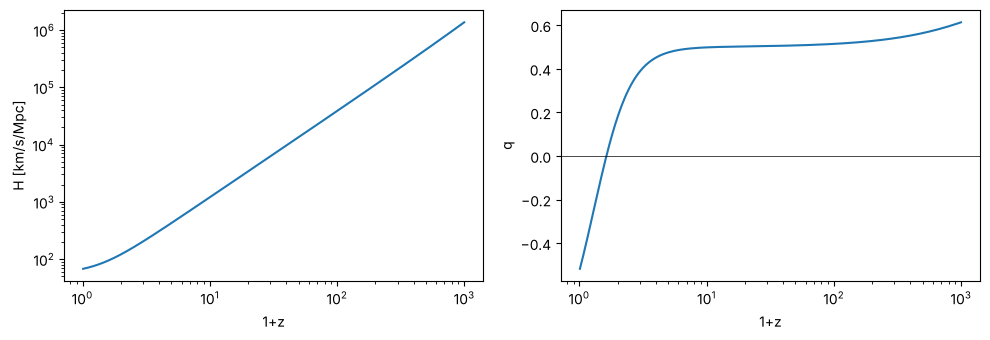

In [3]:
z = np.logspace(-2, 3, 200)
T = expansion_table(bg, z)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].loglog(1 + z, T['H_km_s_Mpc']); ax[0].set_xlabel('1+z'); ax[0].set_ylabel('H [km/s/Mpc]')
ax[1].semilogx(1 + z, T['q']); ax[1].axhline(0, color='k', lw=0.5); ax[1].set_xlabel('1+z'); ax[1].set_ylabel('q')
plt.tight_layout(); plt.show()